# Making Meaning with Language

*The Mathematics of Machine Intelligence · Chapter 10*

Familiar words, a new arrangement, and the tests that show whether a learner composes.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Hold out a combination of known parts (a new pairing, a new arrangement, a longer input), score the answer against an independently specified correct output, and keep the held-out test separate from a random split. State which network and which split each score belongs to, and do not combine them. Passing one held-out combination does not establish competence on every arrangement.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 10, Making Meaning with Language: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def thousands(n):
    return f'{int(n):,}'
UNITS = ('walk', 'look', 'run', 'jump')
DIRECTIONS = ('left', 'right')

def decode_direct(words):
    """A single movement: 'jump', 'jump left' (turn, then jump) or 'turn left'."""
    if len(words) == 1:
        return [words[0]]
    verb, direction = words
    if verb == 'turn':
        return [f'turn {direction}']
    return [f'turn {direction}', verb]

def decode_verb(text):
    words = text.split()
    if len(words) == 3 and words[1] in ('opposite', 'around'):
        verb, how, direction = words
        turn = f'turn {direction}'
        body = [] if verb == 'turn' else [verb]
        return [turn, turn] + body if how == 'opposite' else ([turn] + body) * 4
    return decode_direct(words)

def decode_simple(text):
    if text.endswith(' twice'):
        return decode_verb(text[:-len(' twice')]) * 2
    if text.endswith(' thrice'):
        return decode_verb(text[:-len(' thrice')]) * 3
    return decode_verb(text)

def decode(command):
    """The rulebook. 'x after y' is the actions of y followed by the actions of x."""
    if ' after ' in command:
        x, y = command.split(' after ')
        return decode_simple(y) + decode_simple(x)
    if ' and ' in command:
        x, y = command.split(' and ')
        return decode_simple(x) + decode_simple(y)
    return decode_simple(command)

def split_command(command):
    """(joiner, x, y) for a two-part command, or (None, command, None)."""
    for joiner in ('after', 'and'):
        token = f' {joiner} '
        if token in command:
            x, y = command.split(token)
            return (joiner, x, y)
    return (None, command, None)

@lru_cache(maxsize=1)
def all_commands():
    """Every command of the language, built from the grammar (no recursion, so the list is finite)."""
    directs = [(u,) for u in UNITS]
    directs += [(u, d) for u in UNITS for d in DIRECTIONS]
    directs += [('turn', d) for d in DIRECTIONS]
    verbs = [' '.join(w) for w in directs]
    verbs += [f'{u} {how} {d}' for u in UNITS + ('turn',) for how in ('opposite', 'around') for d in DIRECTIONS]
    simples = [v + suffix for v in verbs for suffix in ('', ' twice', ' thrice')]
    commands = list(simples)
    for x, y in itertools.product(simples, simples):
        commands.append(f'{x} and {y}')
        commands.append(f'{x} after {y}')
    return tuple(commands)

@lru_cache(maxsize=1)
def action_lengths():
    return np.array([len(decode(c)) for c in all_commands()])

@lru_cache(maxsize=1)
def jump_composed_count():
    return sum((1 for c in all_commands() if 'jump' in c.split() and c != 'jump'))
WORDS_IN_RULEBOOK = 13
ACTION_COLOURS = {'walk': TEAL, 'look': GOLD, 'run': TERRA, 'jump': NAVY, 'turn left': GREY, 'turn right': GREY}
EXAMPLES = ['jump twice after walk left', 'jump after run', 'walk twice and look', 'look thrice and run left', 'run left after jump twice', 'turn left and jump thrice', 'look after turn right twice', 'run twice after jump thrice']
EXAMPLE_LABELS = [f'{i + 1}. {c}' for i, c in enumerate(EXAMPLES)]

def draw_blocks(ax, row, actions, label):
    ax.text(-0.1, row + 0.43, label, fontsize=9.5, ha='left', va='bottom', color=NAVY)
    for i, action in enumerate(actions):
        colour = ACTION_COLOURS[action]
        ax.add_patch(Rectangle((i, row - 0.3), 0.92, 0.7, facecolor=colour, edgecolor='white'))
        ax.text(i + 0.46, row + 0.05, action.replace(' ', '\n'), ha='center', va='center', fontsize=7.5, color='#172a3b' if colour == GOLD else 'white')

def decoder_picture(command=0):
    text = EXAMPLES[int(command)]
    joiner, x, y = split_command(text)
    ax_x, ax_y, whole = (decode(x), decode(y), decode(text))
    fig, ax = panels()
    left = ax[0]
    left.grid(False)
    left.spines[['left', 'bottom']].set_visible(False)
    draw_blocks(left, 2.4, ax_x, f'x = {x}')
    draw_blocks(left, 1.2, ax_y, f'y = {y}')
    draw_blocks(left, 0.0, whole, f'x {joiner} y: ' + ('y first, then x' if joiner == 'after' else 'x first, then y'))
    left.set(xlim=(-0.15, 5.4), ylim=(-0.5, 3.3), title='Each part decoded, then joined', xticks=[], yticks=[])
    lengths = [len(decode(c)) for c in EXAMPLES]
    colours = [NAVY if i == int(command) else TEAL for i in range(len(EXAMPLES))]
    bars = ax[1].bar(range(1, len(EXAMPLES) + 1), lengths, color=colours, width=0.65)
    for bar, h in zip(bars, lengths):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, h + 0.35, str(h), va='bottom')
    ring(ax[1], int(command) + 1, lengths[int(command)])
    ax[1].set(xlabel='example number', ylabel='basic actions produced', title='Eight examples', ylim=(0, 6.5), xticks=range(1, len(EXAMPLES) + 1))
    ax[1].grid(axis='x', alpha=0)
    names = ', '.join(whole)
    metrics = {'Actions produced': str(len(whole)), 'Parts decoded separately': '2', 'Rows a lookup table needs': thousands(len(all_commands())), 'Words whose meaning is stored': str(WORDS_IN_RULEBOOK)}
    summary = f"'{text}' splits into x = '{x}' ({len(ax_x)} actions) and y = '{y}' ({len(ax_y)}), and the joining word orders them. The result is {names}. A lookup table would need {thousands(len(all_commands()))} rows; the rulebook stores {WORDS_IN_RULEBOOK} word meanings and the rules."
    calc = f"[[x]] = {', '.join(ax_x)}; [[y]] = {', '.join(ax_y)}. " + (f"For 'after': [[x after y]] = [[y]] then [[x]] = {names}. " if joiner == 'after' else f"For 'and': [[x and y]] = [[x]] then [[y]] = {names}. ") + f'Total {len(whole)} actions. Table rows = {thousands(len(all_commands()))}.'
    if any((w in text.split() for w in ('thrice', 'opposite', 'around'))):
        calc += " The rule for 'thrice' here is the companion's reconstruction, not quoted from the paper."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TOTAL_COMMANDS = 20910
RESULTS = [('random split, 80 percent to train', 99.8, 'top architecture', '4,182 (20 percent)', 'a random fifth of the commands'), ('1 percent of commands to train', 5.0, 'best-overall network', 'not stated', 'most of the commands'), ('2 percent of commands to train', 54.0, 'best-overall network', 'not stated', 'most of the commands'), ('4 percent of commands to train', 93.0, 'best-overall network', 'not stated', 'most of the commands'), ('jump taught only alone', 1.2, 'top architecture for this test', '7,706', 'every command that composes jump'), ('turn left taught only alone', 90.0, 'not stated', 'not stated', 'commands that compose turn left'), ('jump alone plus 32 composed examples', 88.4, 'architecture chosen for the jump test', 'not stated', 'composed jump commands, 32 shown'), ('length split, up to 22 actions to train', 20.8, 'top architecture for this split', '3,920', 'commands needing 24 to 48 actions')]
RESULT_SHORT = ['random split', '1 percent', '2 percent', '4 percent', 'jump alone', 'turn left alone', 'jump + 32', 'length split']
APPROX = {1, 2, 3, 5}

def waffle(ax, percent, caption):
    """Ten by ten cells; the first `percent` cells are filled (the last one partly)."""
    for i in range(100):
        row, col = divmod(i, 10)
        frac = min(max(percent - i, 0.0), 1.0)
        face = (1 - frac) * np.array([1, 1, 1]) + frac * np.array(to_rgb(TEAL))
        ax.add_patch(Rectangle((col, 9 - row), 0.92, 0.92, facecolor=face, edgecolor='#d5d9db', linewidth=0.8))
    ax.set(xlim=(-0.1, 10), ylim=(-1.9, 10), aspect='equal')
    ax.axis('off')
    ax.text(5, -0.6, caption, ha='center', va='top', fontsize=9, color='#172a3b')

def scan_results_picture(result=4):
    i = int(result)
    label, score, network, tested, held = RESULTS[i]
    fig, ax = panels()
    waffle(ax[0], score, 'each filled cell is one of 100 test commands\nanswered exactly right' + (' (about)' if i in APPROX else ''))
    ax[0].set_title(f'{score:g} percent' + (' (about)' if i in APPROX else ''), color=NAVY)
    scores = [r[1] for r in RESULTS]
    colours = [NAVY if k == i else TEAL for k in range(len(RESULTS))]
    ypos = np.arange(len(RESULTS))[::-1]
    ax[1].barh(ypos, scores, color=colours, height=0.65)
    for y, s in zip(ypos, scores):
        tag(ax[1], s + 5, y, f'{s:g}', ha='left', va='center', fontsize=9)
    ring(ax[1], scores[i], ypos[i])
    ax[1].set(yticks=ypos, yticklabels=RESULT_SHORT, xlim=(0, 118), xlabel='percent of test commands answered exactly right', title='Separate tests, separate networks')
    ax[1].grid(axis='y', alpha=0)
    metrics = {'Reported score (percent)': ('about ' if i in APPROX else '') + f'{score:g}', 'Test commands': tested, 'Network': network}
    summary = f"On '{label}' the chapter reports {score:g} percent exact matches. The bars come from different networks on different held-out commands, so there is no single score for the model. The random split alone would have made the networks look fine."
    calc = f'Score = 100 x (commands answered exactly) / (commands tested). Held out: {held}. For the random split alone: of {thousands(TOTAL_COMMANDS)} commands, 80 percent is {thousands(round(0.8 * TOTAL_COMMANDS))} to train and {thousands(round(0.2 * TOTAL_COMMANDS))} to test. Composed jump commands counted from the grammar: {thousands(jump_composed_count())}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def unit_pair(overlap):
    """Two unit vectors in the plane whose cosine is `overlap`."""
    return (np.array([1.0, 0.0]), np.array([overlap, math.sqrt(1 - overlap ** 2)]))

def role_bound(first_word, second_word, role1, role2):
    """Words tied to places: each word's code times its place's code, then added."""
    return np.outer(first_word, role1) + np.outer(second_word, role2)

def binding_distance(word_overlap, role_overlap):
    """Closed form: |(f_walk - f_jump) (x) (r1 - r2)| = |f_walk - f_jump| |r1 - r2| for unit codes."""
    return math.sqrt(2 * (1 - word_overlap)) * math.sqrt(2 * (1 - role_overlap))

def binding_picture(word_overlap=0.0, role_overlap=0.0):
    f_walk, f_jump = unit_pair(word_overlap)
    r1, r2 = unit_pair(role_overlap)
    bag_a, bag_b = (f_walk + f_jump, f_jump + f_walk)
    wj = role_bound(f_walk, f_jump, r1, r2).ravel()
    jw = role_bound(f_jump, f_walk, r1, r2).ravel()
    distance = float(np.linalg.norm(wj - jw))
    fig, ax = panels()
    idx = np.arange(4)
    ax[0].bar(idx - 0.2, wj, width=0.38, color=TEAL, label='walk and jump')
    ax[0].bar(idx + 0.2, jw, width=0.38, color=GOLD, label='jump and walk')
    ax[0].axhline(0, color=GREY, linewidth=0.8)
    ax[0].set(xticks=idx, xticklabels=[f'entry {k + 1}' for k in idx], ylabel='value in the code', title='Words tied to places', ylim=(-0.6, 2.35))
    ax[0].legend(fontsize=9, loc='upper right', ncol=2)
    note = 'the two orders have one code: order is lost' if distance < 1e-09 else 'the two orders have different codes'
    tag(ax[0], 1.5, -0.45, f'plain sums differ by 0; {note}' if distance < 1e-09 else f'plain sums differ by 0; tied codes differ by {sig(distance)}', fontsize=8.5, va='center')
    grid = np.linspace(0, 1, 101)
    for a, style, colour in [(0.0, 'solid', TEAL), (0.5, 'dashed', GOLD), (0.9, 'dotted', TERRA)]:
        chosen = abs(a - word_overlap) < 1e-09
        ax[1].plot(grid, [binding_distance(a, c) for c in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'word codes overlap {a:g}')
    ring(ax[1], role_overlap, distance)
    ax[1].set(xlabel='overlap between the two place codes (cosine)', ylabel='difference between the two orders', title='Distinct places keep order', ylim=(-0.05, 2.15))
    ax[1].legend(fontsize=9, loc='upper right')
    kept = 'no, the two orders collapse to one code' if distance < 1e-09 else 'yes'
    metrics = {'Plain-sum difference': sig(np.linalg.norm(bag_a - bag_b)), 'Tied-code difference': sig(distance), 'Order kept': kept}
    summary = f"A plain sum of word codes gives 'walk and jump' and 'jump and walk' the same total, so their difference is 0. Tying each word to its place first gives a difference of {sig(distance)} at word overlap {word_overlap:g} and place overlap {role_overlap:g}; if the two place codes are identical, order is lost again."
    calc = f'Difference = |f_walk - f_jump| x |r1 - r2| = sqrt(2(1 - {word_overlap:g})) x sqrt(2(1 - {role_overlap:g})) = {sig(math.sqrt(2 * (1 - word_overlap)))} x {sig(math.sqrt(2 * (1 - role_overlap)))} = {sig(distance)}. Plain sum: (f_walk + f_jump) in both orders, difference 0.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CHANCE_TWO_SYMBOLS = 2.8
PEOPLE_RATE = 80.7
CIRCLE_SOURCES = [('people, all queries', 80.7, '25 people, one online study', 'about a quarter (10 of 41 errors)'), ('people, longest answers', 72.5, '29 of 40 answers on two long queries', 'not split out in the chapter'), ('people-study model', 82.4, 'most systematic of ten runs', 'more than half'), ('GPT-4, best condition', 58.0, 'a 2023 model', 'not given in the chapter'), ('GPT-4, random order', 14.0, 'a 2023 model', 'not given in the chapter')]
CIRCLE_SHORT = ['people\nall queries', 'people\nlong answers', 'people-study\nmodel', 'GPT-4 best', 'GPT-4\nrandom order']

def circle_picture(source=2):
    i = int(source)
    label, score, basis, error_profile = CIRCLE_SOURCES[i]
    fig, ax = panels()
    waffle(ax[0], score, 'each filled cell is one of 100 answers that\nmatched the rule-based answer')
    ax[0].set_title(f'{label}: {score:g} percent', color=NAVY)
    scores = [s[1] for s in CIRCLE_SOURCES]
    colours = [NAVY if k == i else TEAL for k in range(len(scores))]
    bars = ax[1].bar(range(len(scores)), scores, color=colours, width=0.65)
    for bar, s in zip(bars, scores):
        tag(ax[1], bar.get_x() + bar.get_width() / 2, s + 4, f'{s:g}', va='bottom', fontsize=9)
    ring(ax[1], i, scores[i])
    ax[1].axhline(CHANCE_TWO_SYMBOLS, color=GREY, linestyle='dashed', linewidth=1.4, label='chance for a two-symbol answer (2.8)')
    ax[1].legend(fontsize=8.5, loc='upper right')
    ax[1].set(xticks=range(len(scores)), xticklabels=CIRCLE_SHORT, ylabel='percent matching the rule-based answer', ylim=(0, 108), title='People and machines compared')
    ax[1].tick_params(axis='x', labelsize=8)
    ax[1].grid(axis='x', alpha=0)
    gap = score - PEOPLE_RATE
    gap_text = '0' if abs(gap) < 1e-09 else f'{gap:+.1f}'
    metrics = {'Matches the rule-based answer (percent)': f'{score:g}', "Points from people's 80.7": gap_text, 'Basis': basis, 'Errors of one circle per word': error_profile}
    summary = f"{label.capitalize()} matched the rule-based answer {score:g} percent of the time, {gap_text} points from the people's 80.7. The people-study model was trained on a mixture set to 80 percent rule-based to approximate people, so its closeness is by design. Nothing here shows that people and models err for the same reasons."
    calc = f'Percent = 100 x matching answers / answers. Recounted from the archive the chapter cites: people gave 176 of 217 exact answers = {100 * 176 / 217:.1f} percent (paper: 80.7), and 29 of 40 on the two longest queries = {100 * 29 / 40:.1f} percent. One-circle-per-word errors: 10 of 41 = {100 * 10 / 41:.1f} percent.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def fisher_interval(r, n, z=1.96):
    """Approximate 95 percent interval for a correlation r measured on n items (Fisher's z, needs n > 3)."""
    if n <= 3:
        raise ValueError('Needs more than 3 items.')
    centre = math.atanh(r)
    half = z / math.sqrt(n - 3)
    return (math.tanh(centre - half), math.tanh(centre + half))

def constructed_sample(n, r, seed):
    rng = np.random.default_rng(seed)
    a = rng.standard_normal(n)
    b = r * a + math.sqrt(1 - r ** 2) * rng.standard_normal(n)
    return (a, b)
ITEM_COUNTS = [5, 10, 20, 40, 80, 160]

def correlation_picture(items=10, r=0.788):
    n = int(items)
    low, high = fisher_interval(r, n)
    a, b = constructed_sample(n, r, 788 + n)
    sample_r = float(np.corrcoef(a, b)[0, 1])
    fig, ax = panels()
    ax[0].scatter(a, b, color=TEAL, s=28, zorder=3)
    ax[0].set(xlabel='score on one scale (standardized)', ylabel='score on the other (standardized)', title=f'One constructed sample: r = {sig(sample_r)}', xlim=(-3.4, 3.4), ylim=(-3.4, 3.4))
    ax[0].set_aspect('equal')
    tag(ax[0], 0, -3.0, f'true r = {sig(r)}; seed {788 + n}', fontsize=9, color='#52606b')
    grid = np.geomspace(4, 200, 100)
    for rr, style, colour in [(0.5, 'dotted', GREY), (0.788, 'dashed', TERRA), (0.9, 'solid', GOLD)]:
        chosen = abs(rr - r) < 1e-09
        lows = [fisher_interval(rr, g)[0] for g in grid]
        highs = [fisher_interval(rr, g)[1] for g in grid]
        colour_line = NAVY if chosen else colour
        ax[1].plot(grid, lows, color=colour_line, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.5, label=f'r = {rr:g}')
        ax[1].plot(grid, highs, color=colour_line, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.5)
    ring(ax[1], n, low)
    ring(ax[1], n, high)
    ax[1].set_xscale('log')
    ax[1].set_xticks([5, 10, 20, 40, 80, 160])
    ax[1].set_xticklabels(['5', '10', '20', '40', '80', '160'])
    ax[1].set(xlabel='number of items', ylabel='plausible range for the true correlation', title='The range narrows slowly', ylim=(-0.4, 1.02))
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Measured correlation': sig(r), 'Items': str(n), '95 percent range': f'{sig(low)} to {sig(high)}', 'Range width': sig(high - low)}
    summary = f"A correlation of {sig(r)} measured on {n} items is compatible with a true value anywhere from {sig(low)} to {sig(high)}. The range narrows only as the square root of the item count. The chapter says ten items are few; this range is the companion's own illustration, not a figure from the paper."
    calc = f'z = atanh({sig(r)}) = {sig(math.atanh(r))}; half-width = 1.96/sqrt({n} - 3) = {sig(1.96 / math.sqrt(n - 3))}. Range = tanh(z -/+ half-width) = {sig(low)} to {sig(high)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SHUFFLED_WORDS = ['jump', 'run', 'walk', 'look', 'left', 'right']
EPISODES_SHOWN = 12
SHUFFLE_SEED = 10

def keep_chance(p, words=6):
    """Chance one word keeps its usual meaning when a share p of episodes is reassigned uniformly at random."""
    return 1 - p + p / words

def shuffle_episodes(p):
    rng = np.random.default_rng(SHUFFLE_SEED)
    draws = rng.random(EPISODES_SHOWN)
    perms = [rng.permutation(6) for _ in range(EPISODES_SHOWN)]
    kept = np.ones((EPISODES_SHOWN, 6), dtype=bool)
    for e in range(EPISODES_SHOWN):
        if draws[e] < p:
            kept[e] = perms[e] == np.arange(6)
    return kept

def shuffle_picture(shuffle_prob=0.95):
    p = float(shuffle_prob)
    kept = shuffle_episodes(p)
    fig, ax = panels()
    for e in range(EPISODES_SHOWN):
        for w in range(6):
            ax[0].add_patch(Rectangle((w, EPISODES_SHOWN - 1 - e), 0.92, 0.88, facecolor=TEAL if kept[e, w] else TERRA, edgecolor='white'))
    ax[0].set(xlim=(0, 6), ylim=(0, EPISODES_SHOWN), title='Twelve practice episodes (seed 10)', xticks=np.arange(6) + 0.46, xticklabels=SHUFFLED_WORDS, yticks=np.arange(EPISODES_SHOWN) + 0.44, yticklabels=[str(EPISODES_SHOWN - k) for k in range(EPISODES_SHOWN)], ylabel='episode')
    ax[0].grid(False)
    ax[0].tick_params(axis='x', labelsize=8.5)
    ax[0].tick_params(axis='y', labelsize=8, length=0)
    ax[0].spines[['left', 'bottom']].set_visible(False)
    ax[0].set_xlabel('teal: usual meaning kept; terracotta: reassigned', fontsize=9)
    grid = np.linspace(0, 1, 101)
    ax[1].plot(grid, keep_chance(grid), color=TERRA, linewidth=2.5, label='learner that trusts word identity')
    ax[1].axhline(1.0, color=TEAL, linewidth=2.5, linestyle='dashed', label='learner that reads the study pairs (ideal)')
    ax[1].axvline(0.95, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.93, 0.78, 'chapter: 95 percent\nof episodes shuffled', fontsize=8.5, ha='right', color='#52606b')
    ring(ax[1], p, keep_chance(p))
    ax[1].set(xlabel='share of practice episodes with meanings shuffled', ylabel="chance a word's usual meaning is right", title='Shuffling makes word identity less reliable', ylim=(0, 1.12), xlim=(-0.02, 1.02))
    ax[1].legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    all_same = int(kept.all(axis=1).sum())
    metrics = {'Episodes shuffled': f'{100 * p:g} percent', 'Chance a word keeps its usual meaning': sig(keep_chance(p)), 'Possible reassignments of 6 words': '720', f'Of {EPISODES_SHOWN} shown, with every word unchanged': str(all_same)}
    if p == 0:
        head = 'With no episodes reassigned, a word always keeps its usual meaning, so nothing pushes a learner to read the study pairs. '
    else:
        head = f'When {100 * p:g} percent of practice episodes reassign the six word meanings at random, a word keeps its usual meaning with chance {sig(keep_chance(p))}. The more is shuffled, the less trusting word identity pays and the more reading the study pairs pays. '
    summary = head + 'Reported add-jump error fell from 99.27 to 0.22 percent with the whole method, not shuffling alone.'
    calc = f"Chance a word keeps its meaning = (1 - p) + p/6 = (1 - {p:g}) + {p:g}/6 = {sig(keep_chance(p))}. Reassignments of six items = 6! = 720. Assumes a uniform random one-to-one reassignment: the paper's Methods use random permutations of the six actions and of the six words, and taking 'random' as uniform is the companion's assumption; the seed 10 is the companion's."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def length_split(cut):
    lengths = action_lengths()
    train = int((lengths <= cut).sum())
    test = int((lengths > cut).sum())
    return (train, test)
CUTS = [8, 12, 16, 20, 22, 26, 30, 36]

def length_picture(cut=22):
    cut = int(cut)
    lengths = action_lengths()
    train, test = length_split(cut)
    counts = np.bincount(lengths, minlength=50)[:50]
    xs = np.arange(1, 49)
    fig, ax = panels()
    colours = [TEAL if x <= cut else TERRA for x in xs]
    ax[0].bar(xs, counts[1:49], color=colours, width=0.85)
    ax[0].axvline(cut + 0.5, color=NAVY, linewidth=1.5)
    ax[0].legend(handles=[Rectangle((0, 0), 1, 1, color=TEAL), Rectangle((0, 0), 1, 1, color=TERRA)], labels=['training', 'test'], fontsize=9, loc='upper right')
    ax[0].set(xlabel='actions the command needs', ylabel='number of commands', title='Every command, by length')
    cuts = np.arange(1, 48)
    shares = [100 * length_split(c)[1] / len(lengths) for c in cuts]
    ax[1].plot(cuts, shares, color=TEAL, linewidth=2.5)
    ax[1].axvline(22, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 23, 55, "the chapter's cut:\n22 actions", fontsize=8.5, ha='left', color='#52606b')
    ring(ax[1], cut, 100 * test / len(lengths))
    ax[1].set(xlabel='longest training command (actions)', ylabel='share of commands held out for test (percent)', title='Where the cut falls', ylim=(0, 102))
    longest_test = int(lengths[lengths > cut].max()) if test else 0
    metrics = {'Training commands': thousands(train), 'Test commands': thousands(test), 'Share held out': f'{100 * test / len(lengths):.1f} percent', 'Longest command (actions)': str(int(lengths.max()))}
    summary = f'Training on commands that need up to {cut} actions leaves {thousands(train)} to train on and {thousands(test)} to test, the longest needing {longest_test}. '
    if cut == 22:
        summary += 'For this chapter cut the chapter reports 20.8 percent for the top architecture, 100 percent error for the meta-trained model and 99.7 percent for least-to-most prompting.'
    else:
        summary += "The chapter's scores (20.8 percent, 100 percent error, 99.7 percent) are for its cut of 22 only (16,990 and 3,920), not for this cut."
    calc = f'Count commands whose rulebook output has at most {cut} actions: {thousands(train)}; the rest, {thousands(test)}, are test. Check: {thousands(train)} + {thousands(test)} = {thousands(train + test)}. No command needs exactly 23 actions, so cuts of 22 and 23 give the same split.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C10-D01: How does a short rulebook decode a command it never saw?

A command joins 'jump twice' and 'walk left' with 'after'. What are the actions, in order, and why does the second part come first?

Each part is decoded on its own from the word meanings. The joining word then decides the order: 'and' keeps the written order and 'after' performs the right-hand part first. Because the rules apply to any parts, a combination never seen before decodes as easily as a familiar one.

$$
[\![x\text{ after }y]\!] = [\![y]\!] \,\|\, [\![x]\!]
$$

**Symbols:** [[x]]: the list of basic actions that command x specifies; ||: joins two action lists, the left one performed first; x, y: the two commands joined by 'after'

**Predict before looking:** Decode 'jump twice after walk left' yourself. Which two actions come first, and does 'after' put the left or the right part first?

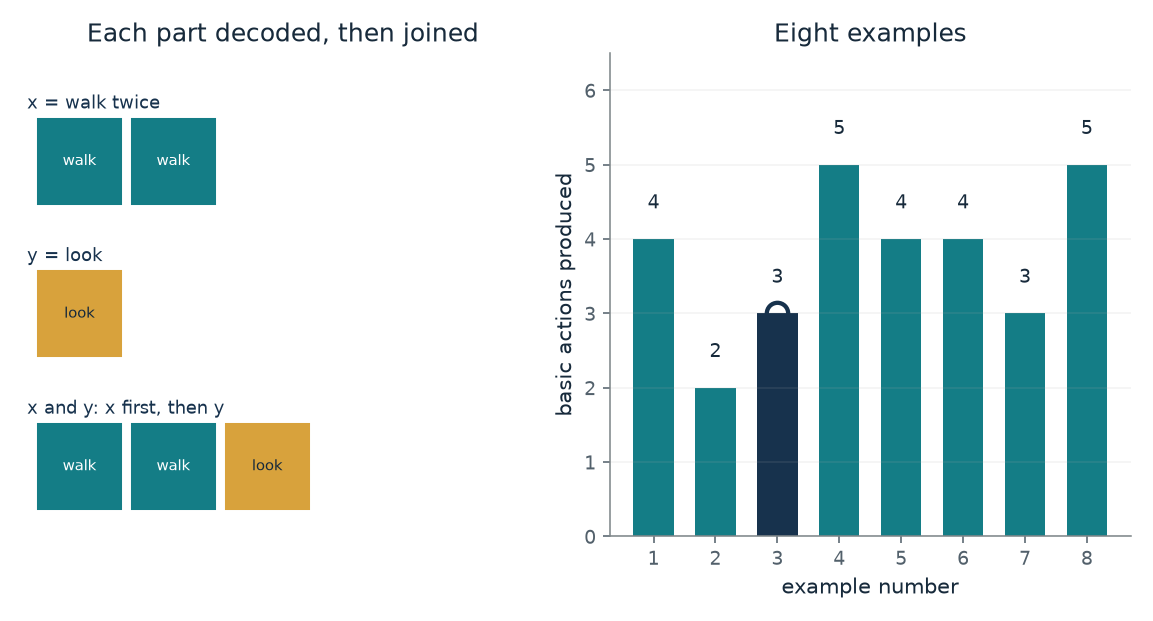

- **Actions produced:** 3
- **Parts decoded separately:** 2
- **Rows a lookup table needs:** 20,910
- **Words whose meaning is stored:** 13

'walk twice and look' splits into x = 'walk twice' (2 actions) and y = 'look' (1), and the joining word orders them. The result is walk, walk, look. A lookup table would need 20,910 rows; the rulebook stores 13 word meanings and the rules.

[[x]] = walk, walk; [[y]] = look. For 'and': [[x and y]] = [[x]] then [[y]] = walk, walk, look. Total 3 actions. Table rows = 20,910.

In [2]:
figure, values, explanation = decoder_picture(**{'command': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a short rulebook decode a command it never saw?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Example command = 0: x = jump twice gives jump, jump; y = walk left gives turn left, walk. 'After' puts y first, so the result is turn left, walk, jump, jump, four actions from two parts of two actions each.

**Takeaway:** A short rulebook decodes every command exactly, while a lookup table would need one row for each of 20,910 commands.

**Why it matters:** The rulebook is the bar a learner is held to: it handles any combination of known words correctly by design, so a network's failure on a new combination is a failure to find the rules from the data it had. In the jump test the data held the lone word only, as the chapter explains.

**In brains and behavior:** The chapter makes no brain claim here; the rulebook is not a model of how a person represents grammar.

**In machines:** The rulebook is a specification, written by a designer, that decodes the artificial language exactly.

**Where it applies:** A finite language with no recursion and unambiguous commands. The rules for 'thrice', 'opposite' and 'around' are the companion's reconstruction, not quoted from the paper; they reproduce the chapter's counts. The rulebook is a specification of the artificial language, not a claim about how a person or a trained network represents grammar.

**Check your understanding:** Decode 'jump after run'. Then say how many rows a lookup table would need for all commands of this language.

<details><summary>Show the answer</summary>

Run comes first, so the actions are run, jump. A lookup table needs one row per command, 20,910, while the rulebook stores the meanings of 13 words and the rules.

</details>

*Source: Chapter 10, A small language with a rulebook. Book formula and worked example (Figure 10.1). The 13 words, 6 actions and 20,910 commands are the chapter's. The rules for 'thrice', 'opposite' and 'around' are the companion's reconstruction, checked by reproducing the chapter's counts (D02 and D07). The lookup-table comparison is constructed, as the chapter says.*

## C10-D02: Why does a score of 99.8 percent not settle whether a network composes?

A network scores 99.8 percent on a random split of the commands. What would you expect it to score on commands that compose a word it saw only alone?

The same kind of network learns a lot from a small share of commands and nearly all of them from a random split, yet it fails on composed commands when a word was only ever seen alone. The 'turn left' word occurs inside many training commands, and composing it scored about 90 percent. Adding 32 composed examples lifted the jump score to 88.4 percent, still described as far from systematic.

$$
\text{score} = 100\times\frac{\text{commands answered exactly right}}{\text{commands tested}}
$$

**Symbols:** score: percent of test commands whose whole action sequence was exactly right; held out: the commands kept out of training and used for the test

**Predict before looking:** The network was right on 99.8 percent of a random split. Predict its score on commands that combine 'jump' with other words when jump appeared in training only by itself.

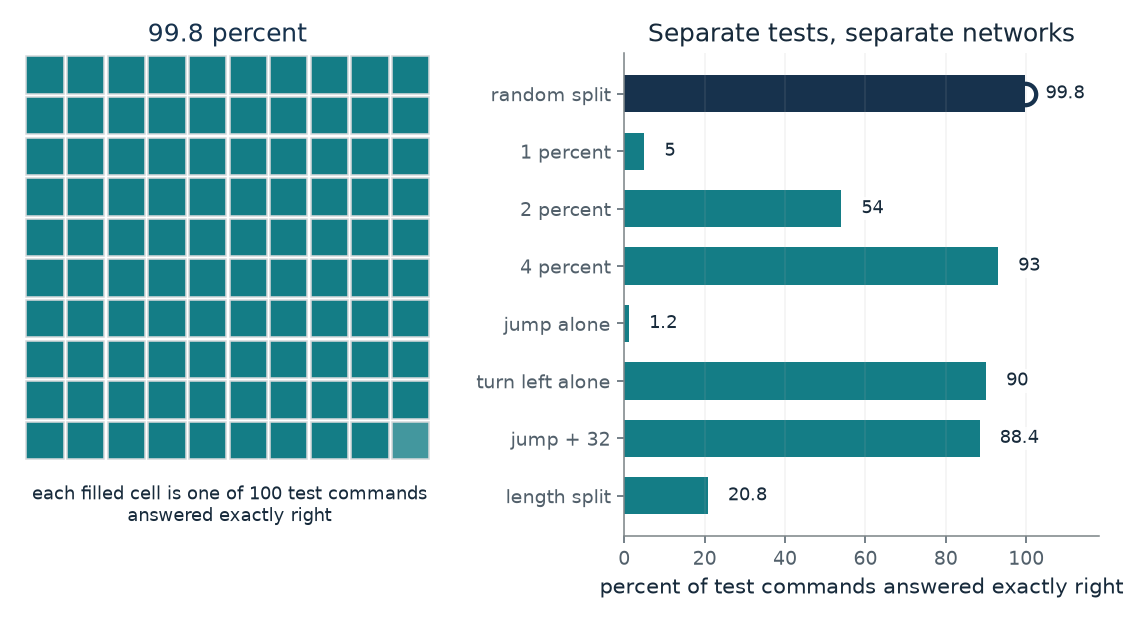

- **Reported score (percent):** 99.8
- **Test commands:** 4,182 (20 percent)
- **Network:** top architecture

On 'random split, 80 percent to train' the chapter reports 99.8 percent exact matches. The bars come from different networks on different held-out commands, so there is no single score for the model. The random split alone would have made the networks look fine.

Score = 100 x (commands answered exactly) / (commands tested). Held out: a random fifth of the commands. For the random split alone: of 20,910 commands, 80 percent is 16,728 to train and 4,182 to test. Composed jump commands counted from the grammar: 7,706.

In [3]:
figure, values, explanation = scan_results_picture(**{'result': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a score of 99.8 percent not settle whether a network composes?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which test = 4: On the composed jump commands the best design scored 1.2 percent, though it scored 95 percent or better on its own training commands. The failure was invisible in the random split.

**Takeaway:** A random split draws test commands from the same pool as training, so it can look excellent while a held-out combination fails.

**Why it matters:** A smooth answer to a familiar command proves nothing about a new one. The test has to hold out the combination.

**In brains and behavior:** No people were tested on SCAN; the authors wrote only that they suspect people would not have problems.

**In machines:** These are measured scores of 2018 recurrent networks, reported by the authors, not a model of behavior.

**Where it applies:** Each bar is a different network on a different held-out set. The chapter notes the paper reports no combined score. The study tested 2018 recurrent networks only, and no people.

**Check your understanding:** A random split sends 80 percent of 20,910 commands to training. How many are left to test, and what share of 100 test commands does a score of 1.2 percent represent?

<details><summary>Show the answer</summary>

20,910 x 0.2 = 4,182 test commands. A score of 1.2 percent is a little more than one command in 100.

</details>

*Source: Chapter 10, The word that stayed alone. Reported result. All scores are quoted from the chapter (Lake and Baroni 2018, recurrent networks). The test counts 4,182, 7,706 and 3,920 follow the chapter's 80 percent split, its jump count and its length split; the 7,706 is also recounted from the grammar. Nothing is simulated.*

## C10-D03: How can a sum of word codes remember order?

Two commands use the same two words in opposite order. Does a plain sum of word codes tell them apart, and what changes if each word is tied to its place first?

Adding word codes is order-free, so both orders give one total. Multiplying each word's code by its place's code before adding gives a different total for each order, by exactly the difference of the words times the difference of the places. If either difference is zero, the two orders collapse again.

$$
\lVert b(\text{walk and jump})-b(\text{jump and walk})\rVert=\lVert f_{\text{walk}}-f_{\text{jump}}\rVert\,\lVert r_1-r_2\rVert,\qquad b(\text{p q})=f_p\otimes r_1+f_q\otimes r_2
$$

**Symbols:** f_p: the code (list of numbers) for word p; r_1, r_2: codes for the first and second place; b: the code for a command: each word's code times its place's code, added; overlap: cosine between two unit codes; 0 means unrelated, 1 means identical

**Predict before looking:** If the two place codes were identical, would the tied sums still tell the two orders apart? Predict before moving the slider to 1.

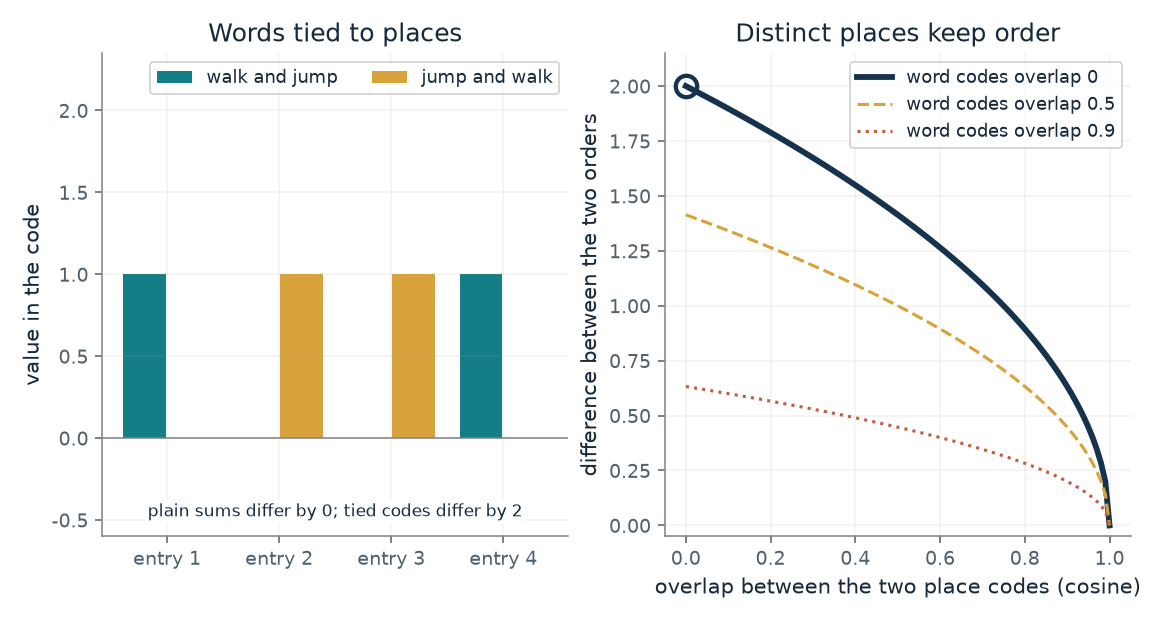

- **Plain-sum difference:** 0
- **Tied-code difference:** 2
- **Order kept:** yes

A plain sum of word codes gives 'walk and jump' and 'jump and walk' the same total, so their difference is 0. Tying each word to its place first gives a difference of 2 at word overlap 0 and place overlap 0; if the two place codes are identical, order is lost again.

Difference = |f_walk - f_jump| x |r1 - r2| = sqrt(2(1 - 0)) x sqrt(2(1 - 0)) = 1.41 x 1.41 = 2. Plain sum: (f_walk + f_jump) in both orders, difference 0.

In [4]:
figure, values, explanation = binding_picture(**{'word_overlap': 0, 'role_overlap': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How can a sum of word codes remember order?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Overlap between the two word codes = 0, Overlap between the two place codes = 0: With unrelated word codes and unrelated place codes the tied codes differ by 2, the largest among the offered overlaps, while the plain sums differ by 0. Slide the place overlap to 1 and the difference falls to 0.

**Takeaway:** Order survives only if the place codes differ; a plain sum, or places that cannot be told apart, treats both orders as one.

**Why it matters:** Whether a network holds a sentence as a sum or as words in places changes which questions it can answer, and the chapter treats the binding idea as a proposal, not a finding.

**In brains and behavior:** Nothing here is measured in a brain. The chapter says people's understanding depends on order and grouping, but gives no brain evidence for binding.

**In machines:** The tied code is a specification of a representation proposed in 1990, not a model of what trained networks do.

**Where it applies:** Two content words, two places, and unit-length codes in a plane. Real networks learn their own codes; this shows only why a sum without places loses order and what tying words to places restores.

**Check your understanding:** Word overlap 0 and place overlap 0.5. By the formula, how much do the tied codes differ for the two orders?

<details><summary>Show the answer</summary>

sqrt(2 x 1) x sqrt(2 x 0.5) = 1.414 x 1 = 1.41. The plain sums still differ by 0.

</details>

*Source: Chapter 10, The word that stayed alone. Constructed example. The chapter's Figure 10.3 is a schematic of this contrast and cites Smolensky's 1990 proposal; the codes here are made-up two-number vectors. The closed form for the difference is the companion's algebra. The chapter says the sources do not test whether binding explains the jump failure.*

## C10-D04: How close did machines come to people on the colored-circle task?

People mostly gave the rule-based answer. A model was trained on a mixture set near 80 percent rule-based. Predict whether it scored below, near or above the people, and how GPT-4 did.

People applied the rule in most answers and still made patterned mistakes: one circle per word, or keeping the written order on the word that reverses it. The model was shaped to match the overall rate, so the interesting comparison is the kind of error. GPT-4 did worse and was badly hurt by shuffling the order of the examples.

$$
\text{percent matching}=100\times\frac{\text{answers matching the rule-based answer}}{\text{answers}}
$$

**Symbols:** rule-based answer: the answer a fixed set of rules gives; the authors call it the algebraic standard; chance: 2.8 percent for a two-symbol answer with the length known

**Predict before looking:** The model was trained with about 80 percent rule-based targets to match people's 80.7. Predict whether its score was below, near or above 80.7, and whether GPT-4 reached it.

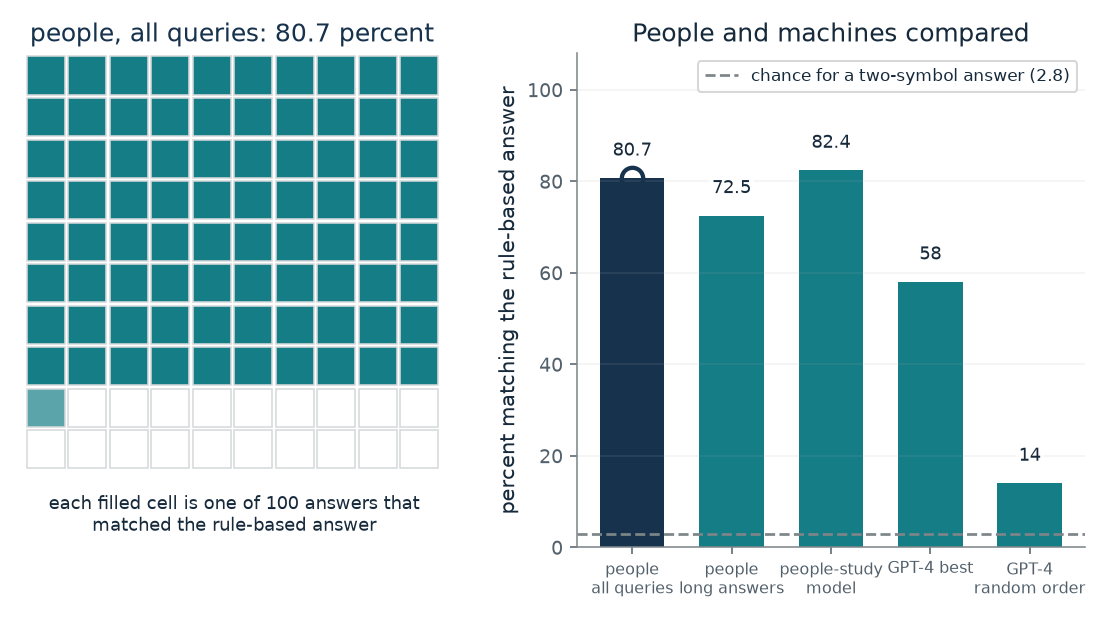

- **Matches the rule-based answer (percent):** 80.7
- **Points from people's 80.7:** 0
- **Basis:** 25 people, one online study
- **Errors of one circle per word:** about a quarter (10 of 41 errors)

People, all queries matched the rule-based answer 80.7 percent of the time, 0 points from the people's 80.7. The people-study model was trained on a mixture set to 80 percent rule-based to approximate people, so its closeness is by design. Nothing here shows that people and models err for the same reasons.

Percent = 100 x matching answers / answers. Recounted from the archive the chapter cites: people gave 176 of 217 exact answers = 81.1 percent (paper: 80.7), and 29 of 40 on the two longest queries = 72.5 percent. One-circle-per-word errors: 10 of 41 = 24.4 percent.

In [5]:
figure, values, explanation = circle_picture(**{'source': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How close did machines come to people on the colored-circle task?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Who answered = 2: The people-study model scored 82.4 percent, near the people's 80.7, as designed. GPT-4 reached 58.0 percent at best and 14.0 with the examples in random order. The model's errors differed: more than half were one circle per word, against about a quarter for people.

**Takeaway:** A model trained to match people's accuracy matches it, and that closeness is a design choice, not evidence that it errs for the same reasons.

**Why it matters:** A score alone does not say how a learner gets there. The pattern of mistakes is a second test, and here it separated people from the model.

**In brains and behavior:** People are known from behavior only, in one online study of 25 people. Their answers are a model target here, not a measurement of how a brain composes.

**In machines:** The transformer is a trained model; its scores are measured outputs on this task, not a specification.

**Where it applies:** One online study of 25 people with no brain measurement. The people-study model's training target was chosen to approximate human accuracy, so the closeness is by design. The GPT-4 and model scores are dated 2023 and may not describe later models.

**Check your understanding:** People gave 176 exact answers out of 217. What percent is that, and how does it compare with the paper's 80.7?

<details><summary>Show the answer</summary>

176/217 = 81.1 percent, about 0.4 points above the paper's 80.7, as the chapter notes of its recount.

</details>

*Source: Chapter 10, A language of colored circles. Reported result, quoted from the chapter (Lake and Baroni 2023 and its supplement). The counts 176 of 217, 29 of 40 and 10 of 41 are the chapter's archive recount. The model's score is the most systematic of ten runs, sampled. Nothing is simulated here.*

## C10-D05: How much does a correlation from ten items settle?

A model's score on each of ten instructions tracked how hard people found them, with a correlation of 0.788. If that came from ten items, what range of true correlations is still plausible?

Fisher's transform makes the spread of a correlation roughly constant, about 1/sqrt(n - 3). A 95 percent range is the transform of r plus and minus 1.96 of that spread, converted back. Quadrupling the items only halves the width of the transformed range.

$$
z=\operatorname{arctanh}(r),\qquad r_{\text{low}},\ r_{\text{high}}=\tanh\!\Big(z\mp\frac{1.96}{\sqrt{n-3}}\Big)
$$

**Symbols:** r: the correlation measured on the items, 1 being a perfect match; n: the number of items; z: Fisher's transform of r, whose spread is approximately 1/sqrt(n - 3)

**Predict before looking:** Predict the low end of the plausible range for 0.788 from ten items. Is it close to 0.788, to 0.5, or lower?

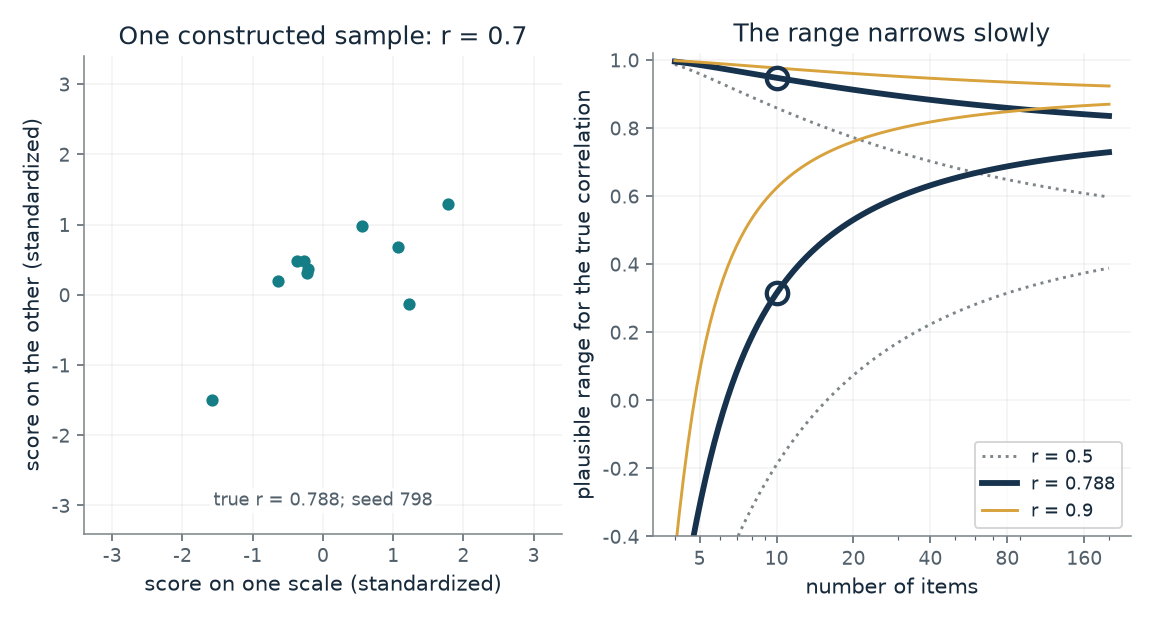

- **Measured correlation:** 0.788
- **Items:** 10
- **95 percent range:** 0.314 to 0.948
- **Range width:** 0.633

A correlation of 0.788 measured on 10 items is compatible with a true value anywhere from 0.314 to 0.948. The range narrows only as the square root of the item count. The chapter says ten items are few; this range is the companion's own illustration, not a figure from the paper.

z = atanh(0.788) = 1.07; half-width = 1.96/sqrt(10 - 3) = 0.741. Range = tanh(z -/+ half-width) = 0.314 to 0.948.

In [6]:
figure, values, explanation = correlation_picture(**{'items': 10, 'r': 0.788})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does a correlation from ten items settle?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of items = 10, Measured correlation = 0.788: The range runs from about 0.31 to 0.95. Even a correlation that looks strong from ten items leaves a true value near 0.3 plausible. With 160 items the same r would be pinned to about 0.72 to 0.84. The paper's own check for ten items was a permutation test (P = 0.031); this range is the companion's illustration.

**Takeaway:** Ten items leave a wide range: the chapter's caution that ten items are few has a number behind it.

**Why it matters:** A single correlation is easy to over-read. Knowing how wide the range is keeps a model-versus-people comparison honest.

**In brains and behavior:** The difficulty ratings come from behavior of 25 people online, not from a brain measurement.

**In machines:** The model's per-instruction scores are measured outputs; the range here is a statistical approximation about the measurement.

**Where it applies:** The usual approximation: items behave like a random sample from a bivariate normal population. Ten instructions are not a random sample, so the range is a guide to how loose the number is, not a verdict. The paper itself reports P = 0.031 for 0.788 by a permutation test over the 10 items (Lake and Baroni 2023); the interval here is the companion's illustration, not the paper's.

**Check your understanding:** For n = 10, what is the half-width in the transformed scale, and what range follows for r = 0.788?

<details><summary>Show the answer</summary>

1.96/sqrt(7) = 0.741 in z units. The transform of 0.788 is 1.066, so the range is tanh(0.325) = 0.314 to tanh(1.807) = 0.947.

</details>

*Source: Chapter 10, A language of colored circles. The 0.788 and the ten items are the chapter's, which says ten items are few. The Fisher interval is the companion's own addition, not in the chapter. The paper itself reports P = 0.031 for this correlation by a two-tailed permutation test over the 10 items; the interval here is the companion's illustration, not the paper's. The scatter is a constructed sample with a disclosed seed, not the study's data.*

## C10-D06: Why does shuffling word meanings make a model read the examples?

If 95 percent of practice episodes reassign what six words mean, how often is a word's usual meaning right, and what does a learner have to do instead?

If a word's meaning is reassigned in most episodes, memorizing that meaning gets it wrong most of the time. The study pairs in the episode always give the current meaning. A learner that reads them can then answer a new word shown once, such as jump with one example.

$$
P(\text{word keeps its meaning})=(1-p)+\frac{p}{6},\qquad 6!=720
$$

**Symbols:** p: the share of practice episodes in which the meanings are reassigned; 6: the six words (jump, run, walk, look, left, right) whose meanings are shuffled; 6!: the number of ways to reassign six items one-to-one

**Predict before looking:** At 95 percent shuffling, predict how often a word keeps its usual meaning. Is it closer to 5 percent, 20 percent or 50 percent?

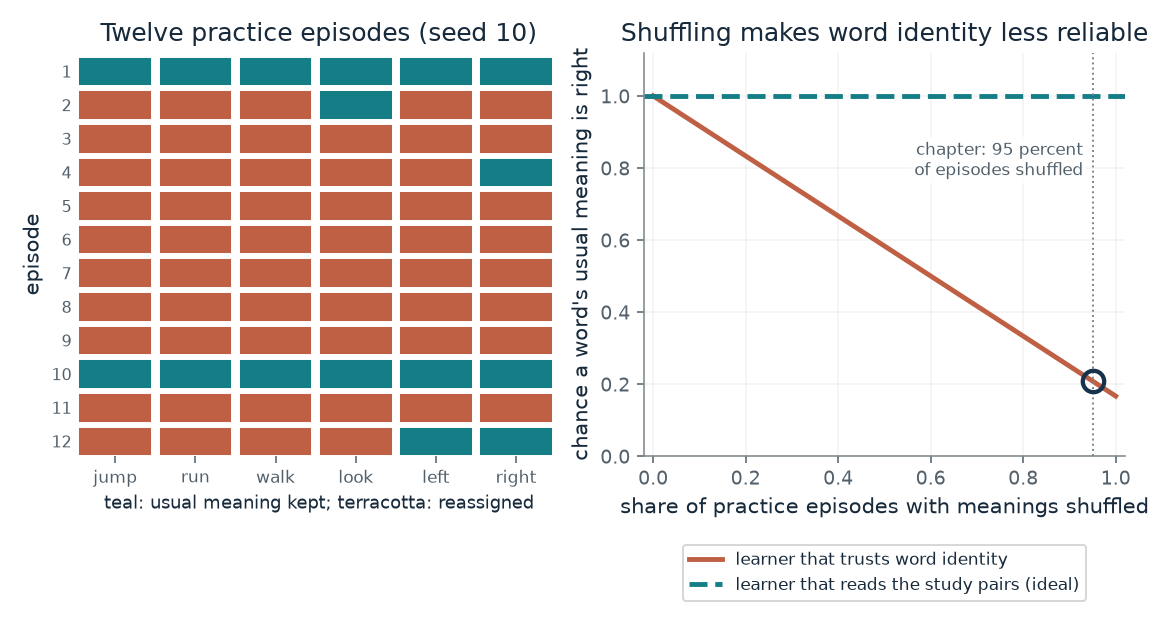

- **Episodes shuffled:** 95 percent
- **Chance a word keeps its usual meaning:** 0.208
- **Possible reassignments of 6 words:** 720
- **Of 12 shown, with every word unchanged:** 2

When 95 percent of practice episodes reassign the six word meanings at random, a word keeps its usual meaning with chance 0.208. The more is shuffled, the less trusting word identity pays and the more reading the study pairs pays. Reported add-jump error fell from 99.27 to 0.22 percent with the whole method, not shuffling alone.

Chance a word keeps its meaning = (1 - p) + p/6 = (1 - 0.95) + 0.95/6 = 0.208. Reassignments of six items = 6! = 720. Assumes a uniform random one-to-one reassignment: the paper's Methods use random permutations of the six actions and of the six words, and taking 'random' as uniform is the companion's assumption; the seed 10 is the companion's.

In [7]:
figure, values, explanation = shuffle_picture(**{'shuffle_prob': 0.95})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does shuffling word meanings make a model read the examples?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of episodes shuffled = 0.95: A word keeps its usual meaning with chance 0.05 + 0.95/6 = 0.208, so trusting word identity is wrong about four times in five. Reading the study pairs is the way to do well here. The reported fall in add-jump error from 99.27 to 0.22 percent compares a basic transformer with the whole meta-learning method, of which shuffling is one part.

**Takeaway:** Shuffling makes word identity unreliable, so a model is pushed to infer meanings from the study examples in each episode.

**Why it matters:** Much of the teaching in the chapter's method is done by the training schedule, not a new network design. The authors call the many-grammar training not developmentally plausible.

**In brains and behavior:** The authors do not claim a child learns this way; nothing here is a brain measurement.

**In machines:** The schedule is a training procedure; the simulated learner is an idealization, not the transformer.

**Where it applies:** A uniform random one-to-one reassignment of the six words' meanings, and an idealized learner that reads the study pairs perfectly. This illustrates the pressure of the training schedule; it is not a model of the network or a measurement.

**Check your understanding:** At 50 percent shuffling, what is the chance a word keeps its usual meaning?

<details><summary>Show the answer</summary>

(1 - 0.5) + 0.5/6 = 0.5 + 0.0833 = 0.583.

</details>

*Source: Chapter 10, Shuffling word meanings. Simulation. The 95 percent, the six words and the 10 study pairs per episode are the chapter's. The paper's Methods remap the six actions through one random permutation and the six words through another, in 95 percent of episodes; the companion simulates this as a uniform one-to-one reassignment of the six meanings (taking 'random' to mean uniform), and the seed 10 is the companion's. The chapter says only that the meanings were reassigned. The reported add-jump errors, 99.27 and 0.22 percent, are the chapter's.*

## C10-D07: What does a length split hold out?

Train on commands that need up to 22 actions and test on the rest. How many commands is that on each side, and does the cut matter?

Decoding gives each command a length. Cutting at a length sends all commands above it to the test set, so every test command is longer than any training command. Moving the cut shows how the held-out share changes, and that no command needs exactly 23 actions.

$$
\text{held out}=\frac{\#\{c:\ |\llbracket c\rrbracket|>L\}}{20{,}910}
$$

**Symbols:** L: the longest command allowed in training, in basic actions; |[[c]]|: the number of basic actions command c produces

**Predict before looking:** The chapter trains on commands that need up to 22 actions. Predict how many of the 20,910 go to the test set: closer to 1 in 100, 1 in 5, or 1 in 2?

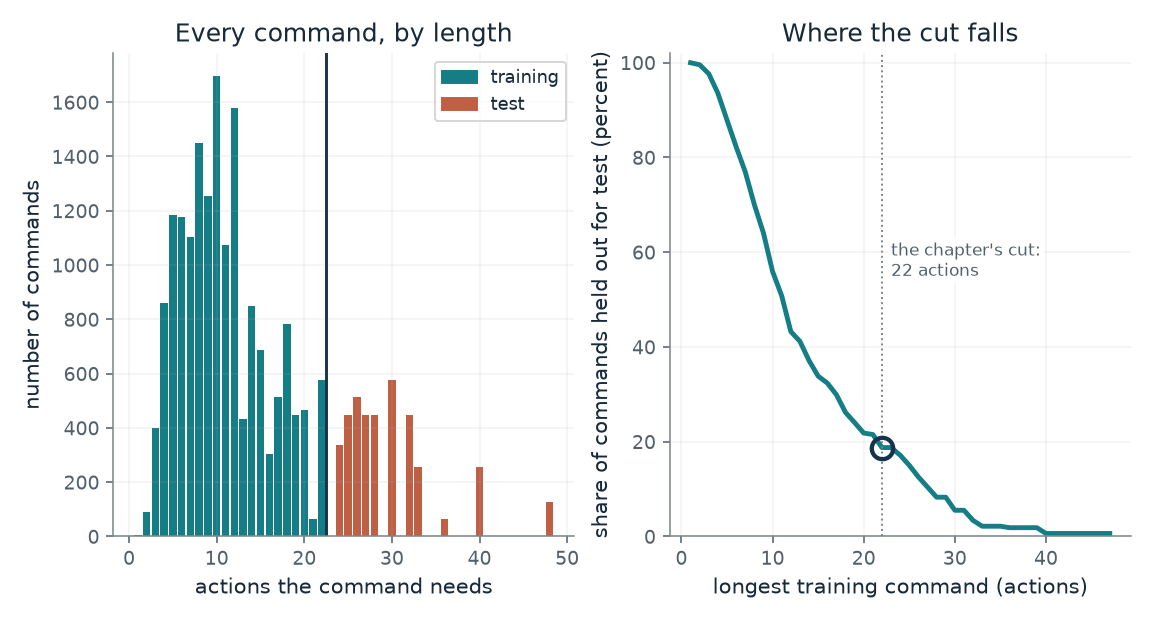

- **Training commands:** 16,990
- **Test commands:** 3,920
- **Share held out:** 18.7 percent
- **Longest command (actions):** 48

Training on commands that need up to 22 actions leaves 16,990 to train on and 3,920 to test, the longest needing 48. For this chapter cut the chapter reports 20.8 percent for the top architecture, 100 percent error for the meta-trained model and 99.7 percent for least-to-most prompting.

Count commands whose rulebook output has at most 22 actions: 16,990; the rest, 3,920, are test. Check: 16,990 + 3,920 = 20,910. No command needs exactly 23 actions, so cuts of 22 and 23 give the same split.

In [8]:
figure, values, explanation = length_picture(**{'cut': 22})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a length split hold out?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Longest training command (actions) = 22: 3,920 of the 20,910 commands, about 1 in 5.3 (18.7 percent), need 24 to 48 actions and form the test. The top network scored 20.8 percent, and 100 percent error for the meta-trained model; this is a different skill from learning a new word.

**Takeaway:** Length is a separate test: every test command is longer than anything in training, so no memorized pattern covers it.

**Why it matters:** The chapter calls this skill productivity and says it is largely distinct from systematicity. A model can pass a new-word test and still fail on length.

**In brains and behavior:** No brain evidence is involved; people were not tested on the length split.

**In machines:** The reported scores are for separately trained 2018 and 2023 models, and one large pretrained model with worked examples reached 99.7 percent by a different route.

**Where it applies:** The rules for 'thrice', 'opposite' and 'around' are the companion's reconstruction, supported by matching the chapter's counts. Other cut points are the companion's variations on the chapter's single split.

**Check your understanding:** At the chapter's cut, what do the two counts add to, and what share is held out?

<details><summary>Show the answer</summary>

16,990 + 3,920 = 20,910. The held-out share is 3,920/20,910 = 18.7 percent.

</details>

*Source: Chapter 10, Longer than practiced. Computation. Command lengths come from decoding all 20,910 commands with the rulebook of D01, which reproduces the chapter's 16,990 training and 3,920 test commands and the 48-action maximum. The reported scores quoted in the summary are the chapter's.*

## Bring it to your own question

Hold out a combination of known parts (a new pairing, a new arrangement, a longer input), score the answer against an independently specified correct output, and keep the held-out test separate from a random split. State which network and which split each score belongs to, and do not combine them. Passing one held-out combination does not establish competence on every arrangement.

Use the `mmi-ch10-making-meaning-language` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.